# Projeto Prático de Machine Learning Supervisionado
## Classificação: a música é explícita? (base de músicas do Spotify, 1998–2020)

## Etapa 1: Contextualização e Formulação da Pergunta

**Origem dos dados.** O arquivo `spotify_songs.csv` reúne 2.000 músicas populares no Spotify entre 1998 e 2020. Cada linha traz o artista, o título, a duração, o ano, a popularidade, o gênero e atributos de áudio calculados pelo Spotify (dançabilidade, energia, valência, tempo e outros).

**Relevância.** Plataformas de streaming precisam sinalizar conteúdo explícito para filtros parentais, para playlists infantis e para regras de publicidade. Hoje essa marcação depende de informação fornecida pela gravadora ou de revisão manual. Um modelo que estime a probabilidade de uma faixa ser explícita a partir de características objetivas pode ajudar a priorizar a revisão de faixas sem marcação.

**Pergunta de negócio.** É possível prever, a partir das características de áudio, do ano, da popularidade e do gênero, se uma música é marcada como explícita?

**Variável alvo (y):** `explicit`, que vale 1 (explícita) ou 0 (não explícita).

**Variáveis de entrada (X):**

| Variável | Significado |
|---|---|
| `duration_ms` | duração da faixa em milissegundos |
| `year` | ano de lançamento |
| `popularity` | popularidade no Spotify (0 a 100) |
| `danceability` | adequação para dança (0 a 1) |
| `energy` | intensidade e atividade percebidas (0 a 1) |
| `key` | tom da música (0 a 11) |
| `loudness` | volume médio em dB |
| `mode` | modo: 1 = maior, 0 = menor |
| `speechiness` | presença de palavras faladas (0 a 1) |
| `acousticness` | confiança de a faixa ser acústica (0 a 1) |
| `instrumentalness` | probabilidade de não ter vocais (0 a 1) |
| `liveness` | probabilidade de ser gravação ao vivo (0 a 1) |
| `valence` | positividade musical (0 a 1) |
| `tempo` | batidas por minuto |
| `genre_*` | uma coluna binária para cada gênero (codificação multi-hot, pois uma música pode ter vários gêneros) |

`artist` e `song` são identificadores de alta cardinalidade e ficam fora do modelo.

**Tipo de aprendizado.** A variável alvo é qualitativa e binária, e os rótulos já existem. Por isso o problema é de **Classificação supervisionada**, não de Regressão. Não se estima uma quantidade contínua, e sim a classe de cada registro. Serão comparados dois modelos: Regressão Logística e Árvore de Decisão.

## Etapa 2: Exploração e Engenharia de Dados

In [1]:
# Importação das bibliotecas utilizadas no projeto
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEMENTE = 42

In [2]:
# Carregamento da base e inspeção inicial: tamanho, tipos das colunas e primeiras amostras
df = pd.read_csv("spotify_songs.csv")
print("Dimensões da base (linhas, colunas):", df.shape)
print()
df.info()

Dimensões da base (linhas, colunas): (2000, 18)

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   artist            2000 non-null   str    
 1   song              2000 non-null   str    
 2   duration_ms       2000 non-null   int64  
 3   explicit          2000 non-null   bool   
 4   year              2000 non-null   int64  
 5   popularity        2000 non-null   int64  
 6   danceability      2000 non-null   float64
 7   energy            2000 non-null   float64
 8   key               2000 non-null   int64  
 9   loudness          2000 non-null   float64
 10  mode              2000 non-null   int64  
 11  speechiness       2000 non-null   float64
 12  acousticness      2000 non-null   float64
 13  instrumentalness  2000 non-null   float64
 14  liveness          2000 non-null   float64
 15  valence           2000 non-null   float64
 16  temp

In [3]:
# Primeiras amostras da base
df.head()

,artist,song,duration_ms,explicit,year,popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,genre
0,Britney Spears,Oops!...I Did It Again,211160,False,2000,77,0.751,0.834,1,-5.444,0,0.0437,0.3000,0.000018,0.3550,0.894,95.053,pop
1,blink-182,All The Small Things,167066,False,1999,79,0.434,0.897,0,-4.918,1,0.0488,0.0103,0.000000,0.6120,0.684,148.726,"rock, pop"
2,Faith Hill,Breathe,250546,False,1999,66,0.529,0.496,7,-9.007,1,0.0290,0.1730,0.000000,0.2510,0.278,136.859,"pop, country"
3,Bon Jovi,It's My Life,224493,False,2000,78,0.551,0.913,0,-4.063,0,0.0466,0.0263,0.000013,0.3470,0.544,119.992,"rock, metal"
4,*NSYNC,Bye Bye Bye,200560,False,2000,65,0.614,0.928,8,-4.806,0,0.0516,0.0408,0.001040,0.0845,0.879,172.656,pop


In [4]:
# Estatísticas descritivas das colunas numéricas
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
duration_ms,2000.0,228748.124,39136.569,113000.000,203580.000,223279.500,248133.000,484146.000
year,2000.0,2009.494,5.860,1998.000,2004.000,2010.000,2015.000,2020.000
popularity,2000.0,59.872,21.336,0.000,56.000,65.500,73.000,89.000
danceability,2000.0,0.667,0.140,0.129,0.581,0.676,0.764,0.975
energy,2000.0,0.720,0.153,0.055,0.622,0.736,0.839,0.999
key,2000.0,5.378,3.615,0.000,2.000,6.000,8.000,11.000
loudness,2000.0,-5.512,1.933,-20.514,-6.490,-5.285,-4.168,-0.276
mode,2000.0,0.554,0.497,0.000,0.000,1.000,1.000,1.000
speechiness,2000.0,0.104,0.096,0.023,0.040,0.060,0.129,0.576
acousticness,2000.0,0.129,0.173,0.000,0.014,0.056,0.176,0.976


### Valores ausentes e duplicados

A verificação abaixo mostra se há valores nulos. Também há um valor que se parece com ausência, mas não é nulo: a coluna `genre` traz o texto `set()` para músicas sem gênero informado. Ele será tratado como categoria própria, `desconhecido`, e não será imputado nem descartado, porque são poucas linhas (cerca de 1%) e a informação "sem gênero" pode ser útil.

Linhas repetidas (mesmo artista e mesma música) são removidas, porque a mesma faixa não pode aparecer ao mesmo tempo no treino e no teste. Isso inflaria artificialmente o desempenho.

In [5]:
# Contagem de valores nulos por coluna
print("Valores nulos por coluna:")
print(df.isna().sum()[df.isna().sum() > 0] if df.isna().sum().sum() > 0 else "Nenhum valor nulo encontrado.")

# Músicas sem gênero aparecem como o texto "set()"
print("\nLinhas com gênero 'set()':", (df["genre"] == "set()").sum())
df["genre"] = df["genre"].replace("set()", "desconhecido")

# Remoção de duplicatas (mesmo artista e mesma música)
print("Linhas duplicadas (artista + música):", df.duplicated(subset=["artist", "song"]).sum())
df = df.drop_duplicates(subset=["artist", "song"]).reset_index(drop=True)
print("Dimensões após a limpeza:", df.shape)

Valores nulos por coluna:
Nenhum valor nulo encontrado.

Linhas com gênero 'set()': 22
Linhas duplicadas (artista + música): 74
Dimensões após a limpeza: (1926, 18)


explicit
False    1393
True      533
Name: count, dtype: int64
explicit
False    72.3 %
True     27.7 %
Name: proportion, dtype: str


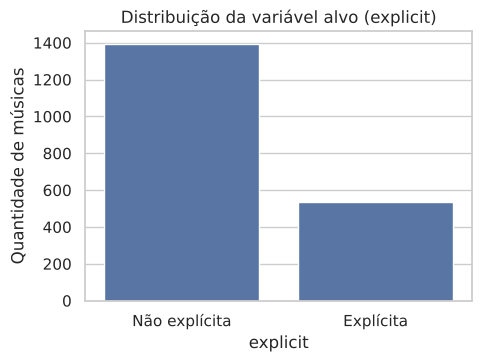

In [6]:
# Distribuição da variável alvo
contagem = df["explicit"].value_counts()
print(contagem)
print((df["explicit"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(x=contagem.index.map({False: "Não explícita", True: "Explícita"}), y=contagem.values, ax=ax)
ax.set_title("Distribuição da variável alvo (explicit)")
ax.set_ylabel("Quantidade de músicas")
plt.show()

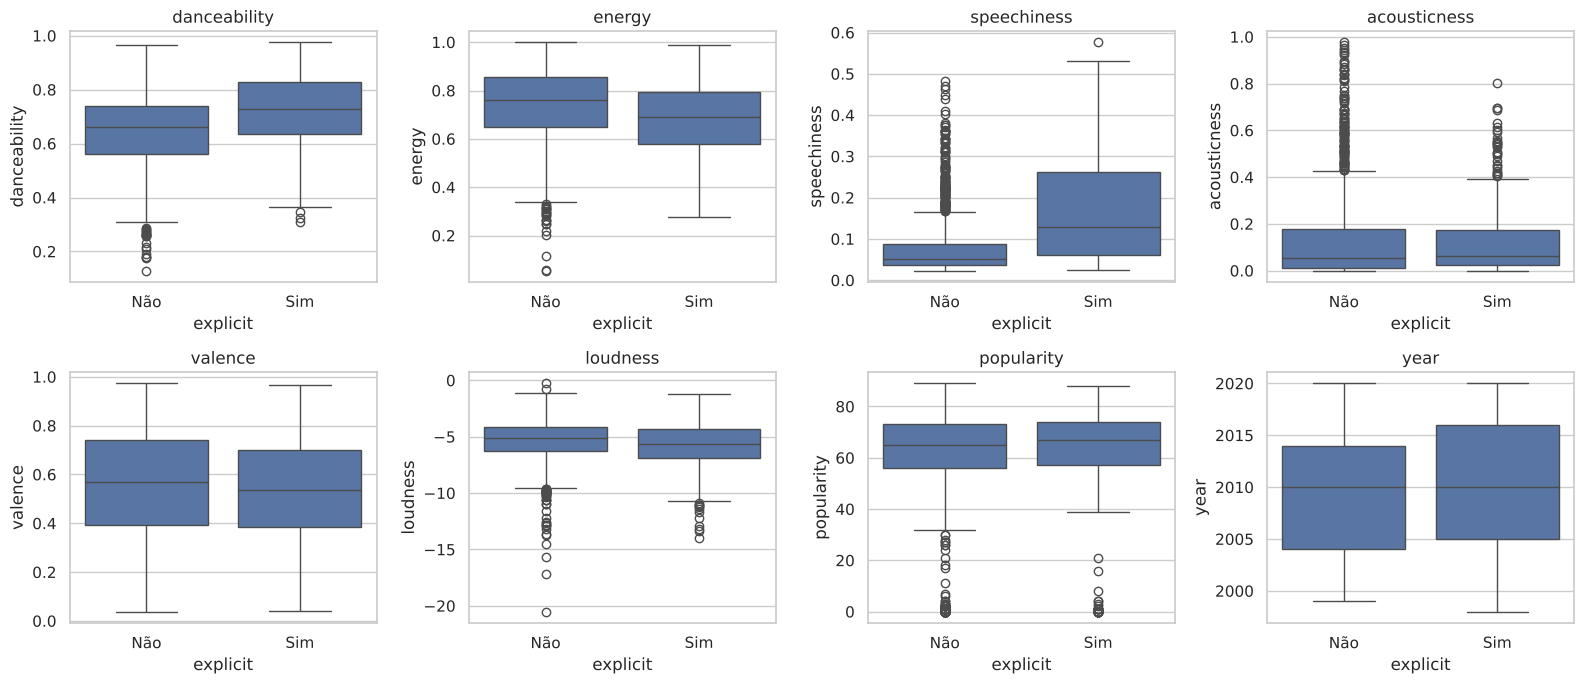

In [7]:
# Comparação das variáveis numéricas entre as duas classes
colunas_num = ["danceability", "energy", "speechiness", "acousticness", "valence", "loudness", "popularity", "year"]
fig, eixos = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(eixos.ravel(), colunas_num):
    sns.boxplot(data=df, x="explicit", y=col, ax=ax)
    ax.set_xticklabels(["Não", "Sim"])
    ax.set_title(col)
plt.tight_layout()
plt.show()

### Codificação de atributos categóricos

A coluna `genre` contém texto, às vezes com vários gêneros separados por vírgula (por exemplo, `"hip hop, pop, R&B"`). Os algoritmos exigem números, e uma música pode pertencer a mais de um gênero. Por isso aplica-se a codificação **multi-hot**: uma coluna binária `genre_<nome>` para cada gênero, com valor 1 quando a música o possui.

In [8]:
# Codificação multi-hot da coluna genre
generos = df["genre"].str.get_dummies(sep=", ")
generos.columns = ["genre_" + c for c in generos.columns]
print("Gêneros codificados:", list(generos.columns))

# Colunas numéricas originais usadas como preditoras
colunas_numericas = ["duration_ms", "year", "popularity", "danceability", "energy", "key", "loudness",
                     "mode", "speechiness", "acousticness", "instrumentalness", "liveness", "valence", "tempo"]

# Matriz de atributos (X) e vetor de resposta (y)
X = pd.concat([df[colunas_numericas], generos], axis=1)
y = df["explicit"].astype(int)

print("\nFormato de X:", X.shape, "| Formato de y:", y.shape)
print("Nulos em X:", int(X.isna().sum().sum()))
X.head()

Gêneros codificados: ['genre_Dance/Electronic', 'genre_Folk/Acoustic', 'genre_R&B', 'genre_World/Traditional', 'genre_blues', 'genre_classical', 'genre_country', 'genre_desconhecido', 'genre_easy listening', 'genre_hip hop', 'genre_jazz', 'genre_latin', 'genre_metal', 'genre_pop', 'genre_rock']

Formato de X: (1926, 29) | Formato de y: (1926,)
Nulos em X: 0


,duration_ms,year,popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,genre_Dance/Electronic,genre_Folk/Acoustic,genre_R&B,genre_World/Traditional,genre_blues,genre_classical,genre_country,genre_desconhecido,genre_easy listening,genre_hip hop,genre_jazz,genre_latin,genre_metal,genre_pop,genre_rock
0,211160,2000,77,0.751,0.834,1,-5.444,0,0.0437,0.3000,0.000018,0.3550,0.894,95.053,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
1,167066,1999,79,0.434,0.897,0,-4.918,1,0.0488,0.0103,0.000000,0.6120,0.684,148.726,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1
2,250546,1999,66,0.529,0.496,7,-9.007,1,0.0290,0.1730,0.000000,0.2510,0.278,136.859,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0
3,224493,2000,78,0.551,0.913,0,-4.063,0,0.0466,0.0263,0.000013,0.3470,0.544,119.992,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1
4,200560,2000,65,0.614,0.928,8,-4.806,0,0.0516,0.0408,0.001040,0.0845,0.879,172.656,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0


## Etapa 3: Particionamento dos Dados (Treino e Teste)

Foram reservados **25%** dos dados para teste, com semente aleatória fixa (`random_state=42`) para reprodutibilidade. Como a base é desbalanceada (as explícitas são minoria), a divisão é **estratificada**, para que treino e teste mantenham a mesma proporção de classes da base original.

In [9]:
# Divisão estratificada em treino (75%) e teste (25%)
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, random_state=SEMENTE, stratify=y
)

proporcoes = pd.DataFrame({
    "Base original": y.value_counts(normalize=True),
    "Treino": y_treino.value_counts(normalize=True),
    "Teste": y_teste.value_counts(normalize=True),
}).round(4)
proporcoes.index = ["Não explícita (0)", "Explícita (1)"]

print("Tamanho do treino:", X_treino.shape[0], "| Tamanho do teste:", X_teste.shape[0])
proporcoes

Tamanho do treino: 1444 | Tamanho do teste: 482


,Base original,Treino,Teste
Não explícita (0),0.7233,0.723,0.7241
Explícita (1),0.2767,0.277,0.2759


## Etapa 4: Construção e Treinamento dos Modelos

**Regressão Logística.** Os atributos têm escalas muito diferentes (`duration_ms` na casa das centenas de milhares e `valence` entre 0 e 1). Por isso a padronização (`StandardScaler`) entra em um *pipeline* com o modelo. O escalonador é ajustado só com os dados de treino, o que evita vazamento de informação do teste. Com `class_weight="balanced"`, os erros na classe minoritária pesam mais.

**Árvore de Decisão.** A profundidade máxima é escolhida por **validação cruzada estratificada (5 dobras) apenas no conjunto de treino**. O conjunto de teste continua isolado. Limitar a profundidade mantém a árvore interpretável e reduz o sobreajuste (*overfitting*).

In [10]:
# Treinamento da Regressão Logística (pipeline com padronização)
modelo_logistico = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEMENTE)
)
modelo_logistico.fit(X_treino, y_treino)
print("Regressão Logística treinada.")

Regressão Logística treinada.


Profundidade escolhida: 3


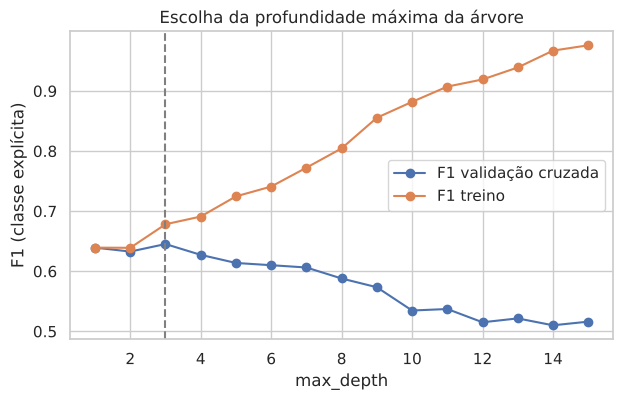

In [11]:
# Escolha da profundidade máxima da árvore por validação cruzada (somente no treino)
validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
profundidades = range(1, 16)
resultados = []
for p in profundidades:
    arv = DecisionTreeClassifier(max_depth=p, class_weight="balanced", random_state=SEMENTE)
    f1_val = cross_val_score(arv, X_treino, y_treino, cv=validacao, scoring="f1").mean()
    f1_trn = arv.fit(X_treino, y_treino).predict(X_treino)
    resultados.append((p, f1_val, f1_score(y_treino, f1_trn)))

tabela_prof = pd.DataFrame(resultados, columns=["max_depth", "F1 validação cruzada", "F1 treino"]).set_index("max_depth")
melhor_prof = int(tabela_prof["F1 validação cruzada"].idxmax())
print("Profundidade escolhida:", melhor_prof)

ax = tabela_prof.plot(marker="o", figsize=(7, 4))
ax.axvline(melhor_prof, color="gray", linestyle="--")
ax.set_ylabel("F1 (classe explícita)")
ax.set_title("Escolha da profundidade máxima da árvore")
plt.show()

In [12]:
# Treinamento da Árvore de Decisão com a profundidade escolhida
modelo_arvore = DecisionTreeClassifier(max_depth=melhor_prof, class_weight="balanced", random_state=SEMENTE)
modelo_arvore.fit(X_treino, y_treino)
print("Árvore de Decisão treinada com max_depth =", melhor_prof)

Árvore de Decisão treinada com max_depth = 3


Intercepto: -0.4993


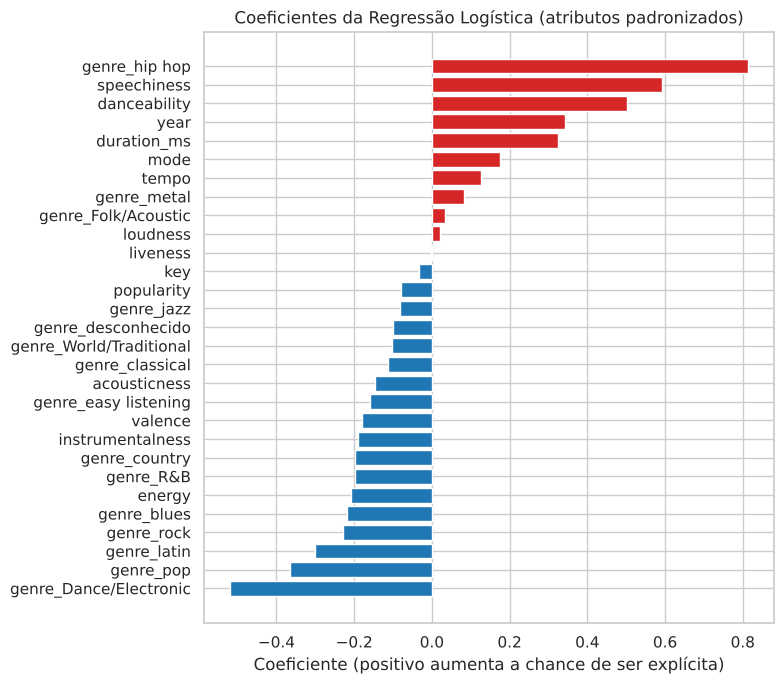

In [13]:
# Coeficientes da Regressão Logística (variáveis padronizadas) e intercepto
regressao = modelo_logistico.named_steps["logisticregression"]
coeficientes = pd.Series(regressao.coef_[0], index=X.columns).sort_values()
print("Intercepto:", round(float(regressao.intercept_[0]), 4))

fig, ax = plt.subplots(figsize=(8, 7))
cores = ["tab:red" if v > 0 else "tab:blue" for v in coeficientes.values]
ax.barh(coeficientes.index, coeficientes.values, color=cores)
ax.set_title("Coeficientes da Regressão Logística (atributos padronizados)")
ax.set_xlabel("Coeficiente (positivo aumenta a chance de ser explícita)")
plt.tight_layout()
plt.show()

In [14]:
# Importância das variáveis na Árvore de Decisão
importancias = pd.Series(modelo_arvore.feature_importances_, index=X.columns).sort_values(ascending=False)
importancias[importancias > 0].round(4).to_frame("importância")

,importância
genre_hip hop,0.7609
speechiness,0.1343
energy,0.0581
liveness,0.0324
valence,0.0143


## Etapa 5: Avaliação Quantitativa e Diagnóstico Visual

In [15]:
# Predições nos dados de teste e métricas de ambos os modelos
modelos = {"Regressão Logística": modelo_logistico, "Árvore de Decisão": modelo_arvore}
previsoes = {nome: m.predict(X_teste) for nome, m in modelos.items()}

linhas = []
for nome, pred in previsoes.items():
    linhas.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_teste, pred),
        "Precisão": precision_score(y_teste, pred),
        "Recall": recall_score(y_teste, pred),
        "F1-Score": f1_score(y_teste, pred),
    })
comparacao = pd.DataFrame(linhas).set_index("Modelo").round(4)

for nome, pred in previsoes.items():
    print("=" * 60)
    print(nome)
    print(classification_report(y_teste, pred, target_names=["Não explícita", "Explícita"], digits=3))

melhor_nome = comparacao["F1-Score"].idxmax()
melhor_modelo = modelos[melhor_nome]
print("Modelo com melhor equilíbrio entre precisão e recall (maior F1):", melhor_nome)
comparacao

Regressão Logística
               precision    recall  f1-score   support

Não explícita      0.904     0.834     0.867       349
    Explícita      0.637     0.767     0.696       133

     accuracy                          0.815       482
    macro avg      0.771     0.800     0.782       482
 weighted avg      0.830     0.815     0.820       482

Árvore de Decisão
               precision    recall  f1-score   support

Não explícita      0.886     0.822     0.853       349
    Explícita      0.608     0.722     0.660       133

     accuracy                          0.795       482
    macro avg      0.747     0.772     0.756       482
 weighted avg      0.809     0.795     0.800       482

Modelo com melhor equilíbrio entre precisão e recall (maior F1): Regressão Logística


,Acurácia,Precisão,Recall,F1-Score
Modelo,,,,
Regressão Logística,0.8154,0.6375,0.7669,0.6962
Árvore de Decisão,0.7946,0.6076,0.7218,0.6598


Verdadeiros negativos: 291 | Falsos positivos: 58
Falsos negativos: 31 | Verdadeiros positivos: 102


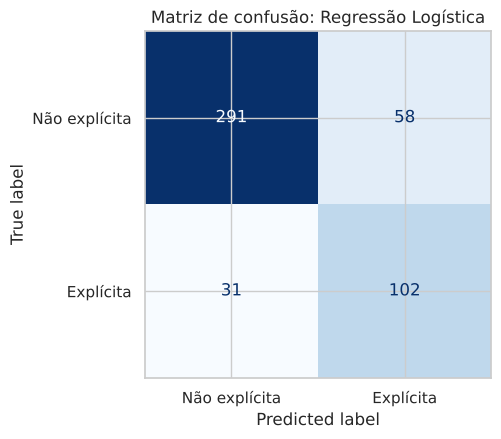

In [16]:
# Matriz de confusão do modelo de melhor desempenho
cm = confusion_matrix(y_teste, previsoes[melhor_nome])
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["Não explícita", "Explícita"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Matriz de confusão: " + melhor_nome)
plt.show()

vn, fp, fn, vp = cm.ravel()
print("Verdadeiros negativos:", vn, "| Falsos positivos:", fp)
print("Falsos negativos:", fn, "| Verdadeiros positivos:", vp)

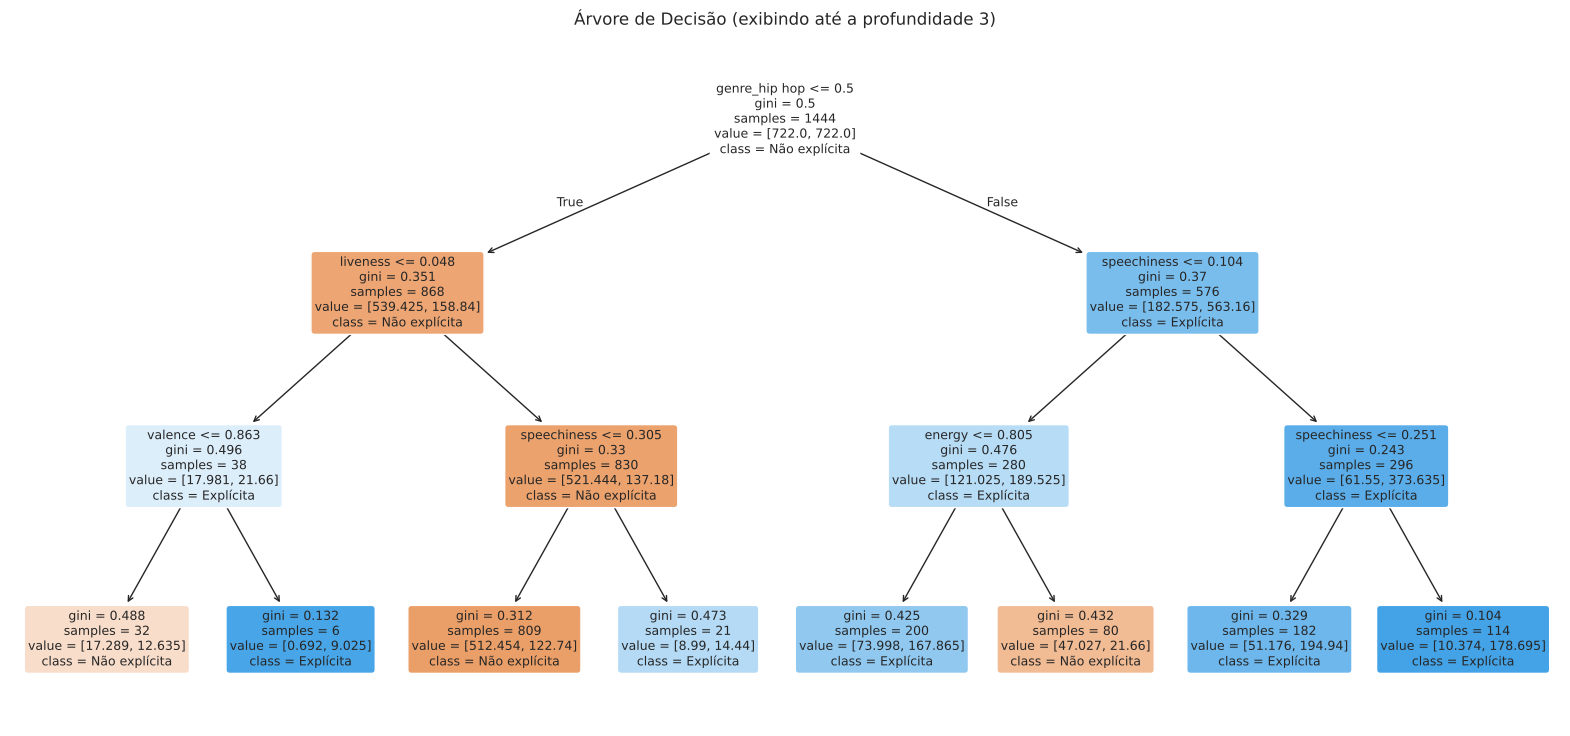

In [17]:
# Estrutura hierárquica das regras aprendidas pela Árvore de Decisão (primeiros 3 níveis)
fig, ax = plt.subplots(figsize=(20, 9))
plot_tree(modelo_arvore, feature_names=list(X.columns), class_names=["Não explícita", "Explícita"],
          max_depth=3, filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title("Árvore de Decisão (exibindo até a profundidade 3)")
plt.show()

## Etapa 6: Simulador Interativo (Inferência com Entrada do Usuário)

A rotina abaixo pede cada valor via `input()`. Basta digitar o valor ou apertar Enter para aceitar o sugerido entre colchetes. Os valores sugeridos descrevem uma faixa de rap típica. Se o ambiente não aceitar entrada de teclado (por exemplo, em uma execução automática), a rotina usa os valores sugeridos e avisa na tela.

O modelo usado é o de melhor desempenho da Etapa 5, e a entrada é montada em uma linha com os mesmos nomes e a mesma ordem de colunas do treinamento.

In [18]:
# Valores sugeridos (faixa de rap típica) e descrição de cada campo
campos = {
    "duration_ms": ("Duração em milissegundos", 240000),
    "year": ("Ano de lançamento", 2005),
    "popularity": ("Popularidade (0 a 100)", 70),
    "danceability": ("Dançabilidade (0 a 1)", 0.80),
    "energy": ("Energia (0 a 1)", 0.70),
    "key": ("Tom (0 a 11)", 5),
    "loudness": ("Volume em dB (ex.: -5.5)", -5.5),
    "mode": ("Modo (1 = maior, 0 = menor)", 0),
    "speechiness": ("Presença de fala (0 a 1)", 0.25),
    "acousticness": ("Acústica (0 a 1)", 0.08),
    "instrumentalness": ("Instrumental (0 a 1)", 0.0),
    "liveness": ("Ao vivo (0 a 1)", 0.15),
    "valence": ("Positividade (0 a 1)", 0.60),
    "tempo": ("Tempo em BPM", 100.0),
}
generos_validos = [c.replace("genre_", "") for c in X.columns if c.startswith("genre_")]
genero_padrao = "hip hop, pop"


def ler_valor(descricao, padrao):
    # Lê um valor do usuário; Enter (ou ausência de teclado) usa o valor sugerido
    try:
        texto = input(f"{descricao} [{padrao}]: ").strip()
    except Exception:
        print(f"{descricao}: entrada indisponível, usando {padrao}")
        return padrao
    return float(texto.replace(",", ".")) if texto else padrao


def coletar_entrada():
    # Coleta os atributos numéricos, converte para float e lê os gêneros
    valores = {nome: float(ler_valor(desc, padrao)) for nome, (desc, padrao) in campos.items()}
    print("Gêneros disponíveis:", ", ".join(generos_validos))
    try:
        texto = input(f"Gêneros separados por vírgula [{genero_padrao}]: ").strip() or genero_padrao
    except Exception:
        print(f"Gêneros: entrada indisponível, usando {genero_padrao}")
        texto = genero_padrao
    escolhidos = [g.strip() for g in texto.split(",")]
    invalidos = [g for g in escolhidos if g not in generos_validos]
    if invalidos:
        print("Gêneros ignorados por não existirem na base:", invalidos)
    return valores, [g for g in escolhidos if g in generos_validos]


def prever(valores, escolhidos):
    # Monta um registro único com as mesmas colunas e ordem do treinamento
    registro = {coluna: 0.0 for coluna in X.columns}
    registro.update(valores)
    for g in escolhidos:
        registro["genre_" + g] = 1.0
    linha = pd.DataFrame([registro], columns=X.columns)
    probabilidades = melhor_modelo.predict_proba(linha)[0]
    classe = int(np.argmax(probabilidades))
    return classe, probabilidades[classe] * 100


print("SIMULADOR - a música é explícita?")
print("-" * 40)
valores_usuario, generos_usuario = coletar_entrada()
classe, confianca = prever(valores_usuario, generos_usuario)

print("\n" + "=" * 40)
print("Classe prevista:", "EXPLÍCITA" if classe == 1 else "NÃO EXPLÍCITA")
print(f"Confiança estimada do modelo: {confianca:.1f}%")
print(f"Modelo utilizado: {melhor_nome}")

SIMULADOR - a música é explícita?
----------------------------------------
Duração em milissegundos [240000]: Duração em milissegundos: entrada indisponível, usando 240000
Ano de lançamento [2005]: Ano de lançamento: entrada indisponível, usando 2005
Popularidade (0 a 100) [70]: Popularidade (0 a 100): entrada indisponível, usando 70
Dançabilidade (0 a 1) [0.8]: Dançabilidade (0 a 1): entrada indisponível, usando 0.8
Energia (0 a 1) [0.7]: Energia (0 a 1): entrada indisponível, usando 0.7
Tom (0 a 11) [5]: Tom (0 a 11): entrada indisponível, usando 5
Volume em dB (ex.: -5.5) [-5.5]: Volume em dB (ex.: -5.5): entrada indisponível, usando -5.5
Modo (1 = maior, 0 = menor) [0]: Modo (1 = maior, 0 = menor): entrada indisponível, usando 0
Presença de fala (0 a 1) [0.25]: Presença de fala (0 a 1): entrada indisponível, usando 0.25
Acústica (0 a 1) [0.08]: Acústica (0 a 1): entrada indisponível, usando 0.08
Instrumental (0 a 1) [0.0]: Instrumental (0 a 1): entrada indisponível, usando 0.0
Ao v

In [19]:
# Segundo teste do simulador, com uma faixa de perfil oposto (pop dançante, sem fala)
valores_pop = {nome: float(padrao) for nome, (desc, padrao) in campos.items()}
valores_pop.update({"year": 2000, "popularity": 65, "danceability": 0.65, "energy": 0.85,
                    "speechiness": 0.04, "acousticness": 0.05, "valence": 0.80, "tempo": 125.0, "mode": 1})
classe, confianca = prever(valores_pop, ["pop"])
print("Classe prevista:", "EXPLÍCITA" if classe == 1 else "NÃO EXPLÍCITA")
print(f"Confiança estimada do modelo: {confianca:.1f}%")

Classe prevista: NÃO EXPLÍCITA
Confiança estimada do modelo: 85.9%


## Etapa 7: Discussão Crítica e Conclusões

### 1. Interpretação das métricas

O melhor modelo foi a **Regressão Logística**, com acurácia de 81,5%, precisão de 63,7%, recall de 76,7% e F1 de 0,696 para a classe explícita. A Árvore de Decisão (profundidade 3) ficou um pouco abaixo, com F1 de 0,660. A diferença é pequena, então a escolha deve considerar também a interpretabilidade.

A acurácia sozinha engana. Como 72% das músicas não são explícitas, um modelo que respondesse "não explícita" para tudo já acertaria cerca de 72%. Por isso o F1 e o recall da classe minoritária são mais informativos. O modelo identifica cerca de 77% das músicas explícitas, mas, entre as que ele marca como explícitas, só 64% realmente são.

**É confiável para decisão real?** Como triagem, sim: serve para priorizar a revisão humana. Como decisão automática e final, não. Cerca de uma em cada três marcações positivas está errada, e uma em cada quatro músicas explícitas passa sem ser detectada. O conjunto de teste tem só 482 músicas (133 explícitas), então as métricas têm margem de incerteza considerável.

### 2. Diagnóstico dos erros (Classificação)

Na matriz de confusão do melhor modelo houve **58 falsos positivos** (músicas limpas marcadas como explícitas) e **31 falsos negativos** (músicas explícitas que passaram como limpas). O modelo erra mais por falso positivo. Isso é esperado, porque o `class_weight="balanced"` deu mais peso à classe minoritária e favoreceu o recall em troca de precisão.

No contexto prático (filtros parentais e playlists infantis), o **falso negativo é a falha mais severa**. Uma música explícita liberada como limpa chega a um público que deveria estar protegido, o que gera dano ao usuário e risco de reputação para a plataforma. O falso positivo causa custo menor: uma música apropriada fica bloqueada ou vai para revisão manual. Por isso é razoável aceitar mais falsos positivos para reduzir os falsos negativos, e o limiar de decisão poderia ser rebaixado ainda mais.

Os coeficientes e a árvore mostram o que sustenta as decisões. O gênero **hip hop** é o fator mais forte (coeficiente +0,81 na regressão e cerca de 76% da importância na árvore). Em seguida vêm `speechiness` (+0,59), `danceability` (+0,50), `year` (+0,34) e `duration_ms` (+0,32). Gêneros como Dance/Electronic (−0,52) e pop (−0,37) reduzem a chance. Ou seja, o modelo aprendeu em grande parte um **proxy de gênero**: as faixas explícitas da base se concentram no hip hop e no R&B de rap. Isso explica a nitidez das previsões para rap e a fragilidade nos casos fora desse padrão, como rock ou pop com letras fortes.

### 3. Limitações e variáveis que poderiam melhorar o sistema

- **Letra da música.** É a fonte direta da classificação. Uma análise do texto (palavras e termos ofensivos) provavelmente superaria qualquer atributo de áudio, que só captura o conteúdo de forma indireta.
- **Dados do artista e da gravadora**, como histórico de lançamentos explícitos, país e selo.
- **Mais dados e mais diversidade.** São 2.000 músicas populares de 1998 a 2020, com 74 duplicatas removidas. A base é dominada por pop e hip hop, e gêneros como jazz e clássica têm quase nenhum exemplo.
- **Rótulo ruidoso.** A marcação "explícita" depende da decisão da gravadora, que varia por época e país. O mesmo conteúdo pode estar marcado de formas diferentes.
- **Variáveis de contexto**, como idioma, região e classificação etária do álbum.
- **Modelos e ajustes.** Modelos de conjunto (Random Forest, Gradient Boosting), ajuste de limiar e validação cruzada para estimar a incerteza das métricas poderiam melhorar o resultado.

### Conclusão

Mesmo sem a letra, atributos de áudio, ano, popularidade e gênero permitem prever com razoável utilidade se uma música é explícita (F1 de 0,70 e recall de 77%), e a Regressão Logística superou a Árvore de Decisão. O resultado é adequado para **triagem assistida**, e a decisão final deve ficar com revisão humana, sobretudo por causa dos falsos negativos.
